```mermaid
---
config:
  theme: base
  themeVariables:
    fontFamily: "Inter, Arial, sans-serif"
    fontSize: "14px"
    primaryColor: "#EFF6FF"
    primaryTextColor: "#1E293B"
    primaryBorderColor: "#93C5FD"
    lineColor: "#94A3B8"
  flowchart:
    curve: basis
    nodeSpacing: 30
    rankSpacing: 45
---
flowchart TB
    START(["LADOT Level of Traffic Stress Assessment"])

    subgraph STREET["1. STREET SEGMENT SCORING"]
        S0{"Bicycle facility present?"}
        S0 -->|Yes| S1{"Protection treatment?"}
        S0 -->|"No - mixed traffic"| S5{"Centerline marked?"}

        subgraph T12["Bicycle facility protection"]
            F1["Permanent dividing median"]
            F2["Parking separation"]
            F3["Permanent civil separation / bus boarding islands"]
            F4["Temporary treatments + parking"]
            F5["Temporary + parking + bus boarding islands"]
            F6["Parking treatments + bus boarding islands"]
            F7["Temporary treatments + bus boarding islands"]
            F8["Striped bike lane without physical barrier"]
            F9["Temporary posts / bollards / K-76s alone"]

            F1 --> SL1["Street LTS 1"]
            F2 --> SL2["Street LTS 2"]
            F3 --> SL2
            F4 --> SL2
            F5 --> SL2
            F6 --> SL2
            F7 --> SL2
            F8 --> SL3["Street LTS 3"]
            F9 --> SL3
        end

        S1 --> F1
        S1 --> F2
        S1 --> F3
        S1 --> F4
        S1 --> F5
        S1 --> F6
        S1 --> F7
        S1 --> F8
        S1 --> F9

        subgraph T3A["Mixed traffic, marked centerline"]
            A0{"Speed limit or prevailing speed?"}

            A0 -->|"≤25 mph"| A25["≤3 lanes: LTS 2<br/>4–5 lanes: LTS 3<br/>6+ lanes: LTS 4"]

            A0 -->|"30 mph"| A30["≤3 lanes: LTS 3<br/>4–5 lanes: LTS 4<br/>6+ lanes: LTS 4"]

            A0 -->|"35+ mph"| A35["≤3 lanes: LTS 4<br/>4–5 lanes: LTS 4<br/>6+ lanes: LTS 4"]
        end

        subgraph T3B["Mixed traffic, unmarked centerline"]
            B0{"Speed limit or prevailing speed?"}

            B0 -->|"≤25 mph"| B25["≤3 lanes: LTS 1<br/>4–5 lanes: LTS 3<br/>6+ lanes: LTS 4"]

            B0 -->|"30 mph"| B30["≤3 lanes: LTS 2<br/>4–5 lanes: LTS 4<br/>6+ lanes: LTS 4"]

            B0 -->|"35+ mph"| B35["≤3 lanes: LTS 4<br/>4–5 lanes: LTS 4<br/>6+ lanes: LTS 4"]
        end

        S5 -->|Yes| A0
        S5 -->|No| B0

        SL1 --> SR["Street LTS score"]
        SL2 --> SR
        SL3 --> SR
        SL4 --> SR
        A25 --> SR
        A30 --> SR
        A35 --> SR
        B25 --> SR
        B30 --> SR
        B35 --> SR
    end

    subgraph INTERSECTION["2. INTERSECTION SCORING"]
        I0{"Intersection control or treatment?"}

        I0 -->|"Controlled + bike box / loop detector"| IL1["Intersection LTS 1"]
        I0 -->|"Traffic signal"| IL2["Intersection LTS 2"]
        I0 -->|"RRFB / Smart Crosswalk"| IL2
        I0 -->|"Refuge-island treatment in Figure 9"| IL3["Intersection LTS 3 - review overlap"]
        I0 -->|Unsignalized| IU{"Crossing island present?"}

        IU -->|No| C0
        IU -->|Yes| D0

        subgraph T4A["Unsignalized, NO crossing island"]
            C0{"Speed limit or prevailing speed?"}

            C0 -->|"≤25 mph"| C25["≤2 lanes: LTS 1<br/>3–5 lanes: LTS 2<br/>6+ lanes: LTS 4"]

            C0 -->|"30 mph"| C30["≤2 lanes: LTS 2<br/>3–5 lanes: LTS 3<br/>6+ lanes: LTS 4"]

            C0 -->|"35 mph"| C35["≤2 lanes: LTS 3<br/>3–5 lanes: LTS 3<br/>6+ lanes: LTS 4"]

            C0 -->|"40+ mph"| C40["≤2 lanes: LTS 3<br/>3–5 lanes: LTS 4<br/>6+ lanes: LTS 4"]
        end

        subgraph T4B["Unsignalized, WITH crossing island"]
            D0{"Speed limit or prevailing speed?"}

            D0 -->|"≤25 mph"| D25["≤2 lanes: LTS 1<br/>4–5 lanes: LTS 2<br/>6+ lanes: LTS 2"]

            D0 -->|"30 mph"| D30["≤2 lanes: LTS 1<br/>4–5 lanes: LTS 2<br/>6+ lanes: LTS 3"]

            D0 -->|"35 mph"| D35["≤2 lanes: LTS 2<br/>4–5 lanes: LTS 3<br/>6+ lanes: LTS 4"]

            D0 -->|"40+ mph"| D40["≤2 lanes: LTS 3<br/>4–5 lanes: LTS 4<br/>6+ lanes: LTS 4"]
        end

        IL1 --> IR["Intersection LTS score"]
        IL2 --> IR
        IL3 --> IR
        C25 --> IR
        C30 --> IR
        C35 --> IR
        C40 --> IR
        D25 --> IR
        D30 --> IR
        D35 --> IR
        D40 --> IR
    end

    subgraph GRADE["3. STREET GRADE — TABLE 5"]
        G0{"Roadway slope?"}
        G0 -->|"0–4%"| G1["Grade LTS 1"]
        G0 -->|"4–6%"| G2["Grade LTS 2"]
        G0 -->|"6–8%"| G3["Grade LTS 3"]
        G0 -->|"8% and up"| G4["Grade LTS 4"]
    end

    subgraph VARIABILITY["4. TRAFFIC VARIABILITY"]
        V0{"Peak-hour tow-away zone?"}
        V0 -->|Yes| V3["Minimum LTS 3"]
        V0 -->|No| VN["No additional minimum"]
    end

    START --> S0
    START --> I0
    START --> G0
    START --> V0

    SR --> FINAL
    IR --> FINAL
    G1 --> FINAL
    G2 --> FINAL
    G3 --> FINAL
    G4 --> FINAL
    V3 --> FINAL
    VN --> FINAL

    FINAL["Overall LTS = MAX of street, relevant intersections, grade and variability"]
    FINAL --> RESULT(["Final LADOT LTS: 1–4"])

    classDef decision fill:#FFF7ED,stroke:#F59E0B,color:#92400E,stroke-width:1.5px
    classDef table fill:#EFF6FF,stroke:#93C5FD,color:#1E3A8A,stroke-width:1px
    classDef result fill:#DCFCE7,stroke:#16A34A,color:#166534,stroke-width:2px
    classDef high fill:#FEE2E2,stroke:#DC2626,color:#991B1B,stroke-width:2px
    classDef warning fill:#FEF3C7,stroke:#D97706,color:#92400E

    class S0,S1,S5,S8,A0,B0,I0,IU,C0,D0,G0,V0 decision
    class F1,F2,F3,F4,F5,F6,F7,F8,F9,A25,A30,A35,B25,B30,B35,C25,C30,C35,C40,D25,D30,D35,D40 table
    class SL1,SL2,SL3,IL1,IL2,G1,G2,SR,IR,VN,FINAL,RESULT result
    class SL4,IL3,G3,G4,V3 high

    style STREET fill:#F8FAFC,stroke:#CBD5E1
    style T12 fill:#F0F9FF,stroke:#BFDBFE
    style T3A fill:#F0F9FF,stroke:#BFDBFE
    style T3B fill:#F0F9FF,stroke:#BFDBFE
    style INTERSECTION fill:#F8FAFC,stroke:#CBD5E1
    style T4A fill:#F0F9FF,stroke:#BFDBFE
    style T4B fill:#F0F9FF,stroke:#BFDBFE
    style GRADE fill:#F8FAFC,stroke:#CBD5E1
    style VARIABILITY fill:#F8FAFC,stroke:#CBD5E1

```

In [1]:
LADOT_BIKEWAYS = "https://services1.arcgis.com/tp9wqSVX1AitKgjd/arcgis/rest/services/LA_City_Bikeways/FeatureServer/0"



In [2]:
import json

FEATURE_SCHEMA = {
    "street": {
        "bicycle_facility_present": None,
        "permanent_dividing_median": None,
        "parking_separation": None,
        "permanent_civil_separation": None,
        "bus_boarding_island": None,
        "temporary_treatments": None,
        "striped_bike_lane": None,
        "physical_barrier_present": None,
        "flexible_posts_or_bollards": None
    },
    "lane_analysis": {
        "road_direction": "unknown",
        "same_direction_through_lanes": None,
        "opposite_direction_through_lanes": None,
        "total_through_lanes": None,
        "turn_only_lanes": None,
        "parking_lanes": None,
        "centerline_type": "unknown",
        "lane_markings": [],
        "lane_count_evidence": "",
        "uncertainty_reason": None
    },
    "intersection": {
        "intersection_visible": None,
        "controlled_intersection": None,
        "traffic_signal_present": None,
        "bike_box_present": None,
        "loop_detector_markings_visible": None,
        "rrfb_present": None,
        "smart_crosswalk_present": None,
        "refuge_island_present": None,
        "crossing_island_present": None,
        "unsignalized": None,
        "number_of_crossed_lanes": None
    },
    "evidence": {}
}

PROMPT = f"""
You are analyzing a street-level photograph for
bicycle Level of Traffic Stress (LTS) research.

Identify ONLY features visible in the image.

Do NOT calculate an LTS score.

GENERAL RULES:
1. Return valid JSON only.
2. Preserve every field in the supplied schema.
3. Use true when clearly present.
4. Use false only when the relevant area is
   sufficiently visible to establish absence.
5. Use null when unknown, hidden, or ambiguous.
6. Do not infer posted speed, AADT, road grade,
   or traffic regulations from appearances.
7. Count only identifiable through lanes.
   Do not count parking or turn-only lanes.
8. Do not invent features outside the camera view.

Analyze the travel-lane configuration in this
street-level image.

Count THROUGH lanes across the entire roadway,
not only the lane containing the camera.

Follow this procedure:

1. Locate the road centerline, if visible.
2. Identify the camera's travel direction.
3. Identify each lane traveling in the same
   direction as the camera.
4. Identify lanes in the opposite direction.
5. Exclude parking lanes, bicycle lanes,
   shoulders, and turn-only lanes.
6. Do not assume all visible pavement is a
   through lane.
7. Use pavement markings, centerlines, vehicle
   orientation, and signs as evidence.
8. If a lane's function cannot be determined,
   report it as uncertain rather than guessing.


All counts must be integers or null.
For known directional counts, the total must
equal their sum.

FEATURE DEFINITIONS:

parking_separation:
A bicycle facility is separated from moving traffic
by a row of parked vehicles. Parked vehicles alongside
an ordinary bike lane do not qualify.

permanent_dividing_median:
A constructed median that physically divides the
relevant traffic or bicycle facility.

permanent_civil_separation:
A raised curb, concrete barrier, or other constructed
physical separation between bicycles and traffic.
An ordinary sidewalk curb does not qualify.

bus_boarding_island:
A raised passenger boarding area separated from
the sidewalk by a bicycle facility.

temporary_treatments:
Flexible posts, delineators, or modular quick-build
devices separating bicycles from moving traffic.

striped_bike_lane:
A recognizable bicycle lane delineated by pavement
markings. This can coexist with physical protection.

physical_barrier_present:
A physical separating element associated with the
bicycle facility, rather than paint alone.

flexible_posts_or_bollards:
Visible flexible vertical delineators or bollards
along the bicycle facility.

bike_box_present:
A designated bicycle waiting area at an intersection,
typically ahead of motor-vehicle stop lines.

loop_detector_markings_visible:
Visible pavement markings or saw cuts suggesting an
inductive detector. Do not claim the detector itself
is confirmed or operational.

rrfb_present:
A rectangular rapid-flashing beacon installation
at a pedestrian crossing.

refuge_island_present:
A raised island providing pedestrian or bicycle
refuge while crossing traffic.

crossing_island_present:
A median or island positioned to divide a crossing
into stages.

smart_crosswalk_present:
Recognizable active crossing equipment.
Use null if the specific equipment is unclear.

For "evidence", provide brief descriptions for
clearly identified features and noteworthy
uncertainties. Do not speculate.

Return this exact JSON structure, replacing null
values with observations where justified:

{json.dumps(FEATURE_SCHEMA, indent=2)}
"""

In [3]:

from pathlib import Path
from PIL import Image, ImageOps
import torch

def analyze_image(image_path):
    image_path = Path(image_path).expanduser().resolve()

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Decode using Pillow instead of torchvision.
    with Image.open(image_path) as img:
        image = ImageOps.exif_transpose(img).convert("RGB")

    print(f"Loaded: {image_path.name}")
    print(f"Image size: {image.size}")

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,  # Pass PIL object, not path.
                },
                {
                    "type": "text",
                    "text": PROMPT,
                },
            ],
        }
    ]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt",
    ).to(model.device)

    inputs.pop("token_type_ids", None)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=4096,
            do_sample=False,
        )

    generated = outputs[
        :, inputs["input_ids"].shape[-1]:
    ]

    return processor.batch_decode(
        generated,
        skip_special_tokens=True,
    )[0]

def parse_result(raw_text):
    decoder = json.JSONDecoder()

    # Handles possible introductory text or code fences.
    for pos, char in enumerate(raw_text):
        if char != "{":
            continue

        try:
            result, _ = decoder.raw_decode(raw_text[pos:])
        except json.JSONDecodeError:
            continue

        if not isinstance(result, dict):
            continue

        required = {"street", "intersection", "evidence"}

        if not required.issubset(result):
            continue

        for section in ("street", "intersection"):
            expected = FEATURE_SCHEMA[section]
            actual = result[section]

            if not isinstance(actual, dict):
                raise ValueError(f"Invalid {section} object")

            if set(actual) != set(expected):
                raise ValueError(
                    f"Incorrect fields in {section}"
                )

            for key, value in actual.items():
                if key.startswith("number_of_"):
                    valid = (
                        value is None
                        or (
                            isinstance(value, int)
                            and not isinstance(value, bool)
                            and value >= 0
                        )
                    )
                else:
                    valid = (
                        value is None
                        or isinstance(value, bool)
                    )

                if not valid:
                    raise ValueError(
                        f"Invalid value: {section}.{key}"
                    )

        if not isinstance(result["evidence"], dict):
            raise ValueError("Invalid evidence object")

        return result

    raise ValueError("No valid LTS JSON found")
    

In [4]:
import os
from pathlib import Path

# Set before importing Hugging Face libraries.
os.environ["HF_HOME"] = str(Path.home() / "ai/huggingface")

import torch
from transformers import (
    AutoProcessor,
    AutoModelForMultimodalLM,
)

model_id = "zai-org/GLM-4.6V-Flash"

processor = AutoProcessor.from_pretrained(model_id)

model = AutoModelForMultimodalLM.from_pretrained(
    model_id,
    dtype=torch.bfloat16,
    device_map="auto",
)

model.eval()

Loading weights:   0%|          | 0/704 [00:00<?, ?it/s]

Glm4vForConditionalGeneration(
  (model): Glm4vModel(
    (visual): Glm4vVisionModel(
      (embeddings): Glm4vVisionEmbeddings(
        (position_embedding): Embedding(576, 1536)
      )
      (patch_embed): Glm4vVisionPatchEmbed(
        (proj): Conv3d(3, 1536, kernel_size=(2, 14, 14), stride=(2, 14, 14))
      )
      (rotary_pos_emb): Glm4vVisionRotaryEmbedding()
      (blocks): ModuleList(
        (0-23): 24 x Glm4vVisionBlock(
          (norm1): Glm4vRMSNorm((1536,), eps=1e-05)
          (norm2): Glm4vRMSNorm((1536,), eps=1e-05)
          (attn): Glm4vVisionAttention(
            (qkv): Linear(in_features=1536, out_features=4608, bias=False)
            (proj): Linear(in_features=1536, out_features=1536, bias=False)
          )
          (mlp): Glm4VisionMlp(
            (gate_proj): Linear(in_features=1536, out_features=4096, bias=False)
            (up_proj): Linear(in_features=1536, out_features=4096, bias=False)
            (down_proj): Linear(in_features=4096, out_features=1

Found 17 image(s)


### 1/17 — `{1362819B-DEE5-48BC-BF4D-F0A49996C04C}.png`

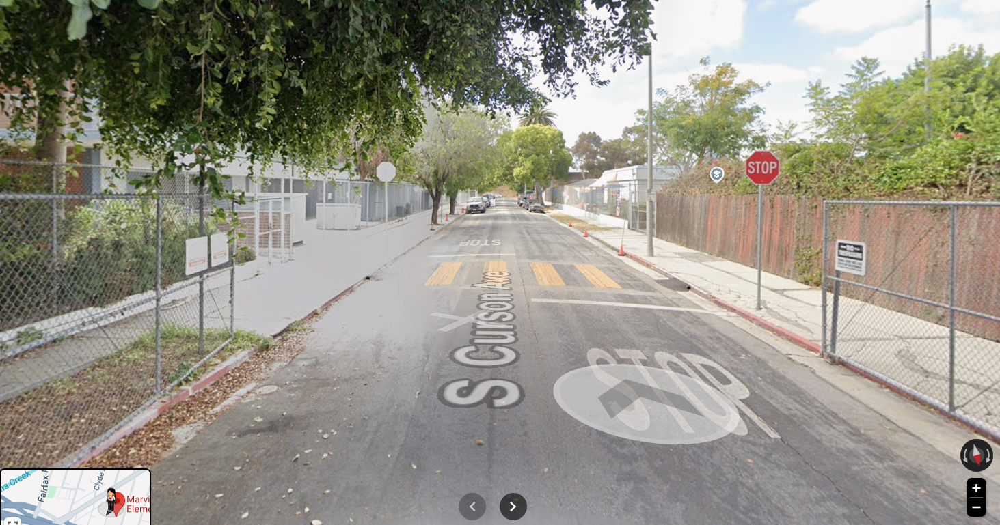

Loaded: {1362819B-DEE5-48BC-BF4D-F0A49996C04C}.png
Image size: (1463, 769)
{
  "street": {
    "bicycle_facility_present": null,
    "permanent_dividing_median": null,
    "parking_separation": null,
    "permanent_civil_separation": null,
    "bus_boarding_island": null,
    "temporary_treatments": null,
    "striped_bike_lane": null,
    "physical_barrier_present": null,
    "flexible_posts_or_bollards": null
  },
  "lane_analysis": {
    "road_direction": "forward",
    "same_direction_through_lanes": 1,
    "opposite_direction_through_lanes": 1,
    "total_through_lanes": 2,
    "turn_only_lanes": null,
    "parking_lanes": null,
    "centerline_type": "unknown",
    "lane_markings": [],
    "lane_count_evidence": "The road shows one lane in the direction of travel (camera) and one lane in the opposite direction, as indicated by vehicle positions in the distance and road geometry.",
    "uncertainty_reason": null
  },
  "intersection": {
    "intersection_visible": true,
    "contr

### 2/17 — `{292B84A0-432D-47C5-9681-621BE61894AD}.png`

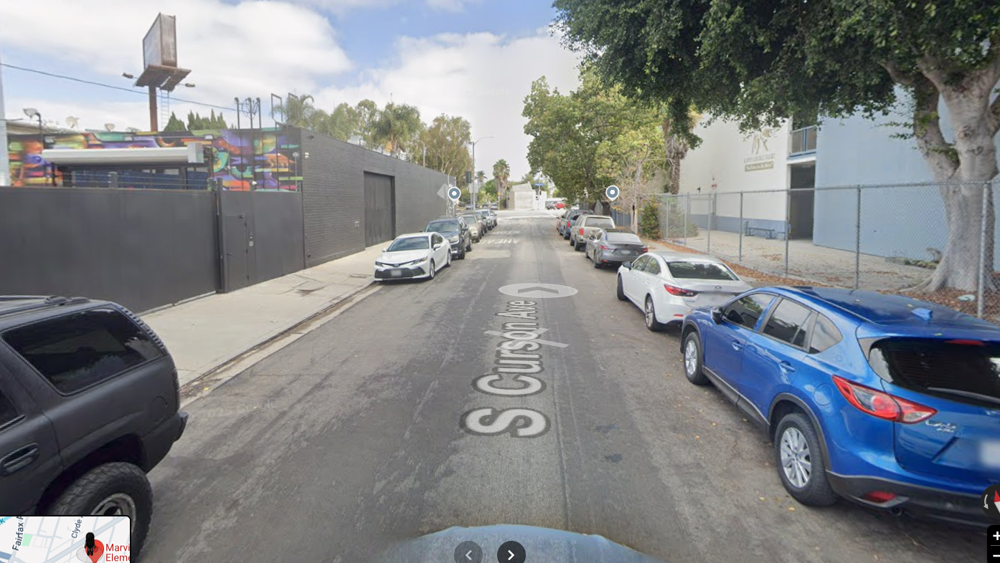

Loaded: {292B84A0-432D-47C5-9681-621BE61894AD}.png
Image size: (1394, 786)
{
  "street": {
    "bicycle_facility_present": null,
    "permanent_dividing_median": null,
    "parking_separation": null,
    "permanent_civil_separation": null,
    "bus_boarding_island": null,
    "temporary_treatments": null,
    "striped_bike_lane": null,
    "physical_barrier_present": null,
    "flexible_posts_or_bollards": null
  },
  "lane_analysis": {
    "road_direction": "southbound",
    "same_direction_through_lanes": 1,
    "opposite_direction_through_lanes": 1,
    "total_through_lanes": 2,
    "turn_only_lanes": null,
    "parking_lanes": null,
    "centerline_type": "dashed",
    "lane_markings": [
      "centerline (dashed)",
      "street name (S Curson Ave)"
    ],
    "lane_count_evidence": "Two through lanes are visible, one in each direction, separated by a dashed centerline.",
    "uncertainty_reason": null
  },
  "intersection": {
    "intersection_visible": null,
    "controlled_inte

### 3/17 — `{49F656A9-51D7-48E8-9A03-637BE33F64A1}.png`

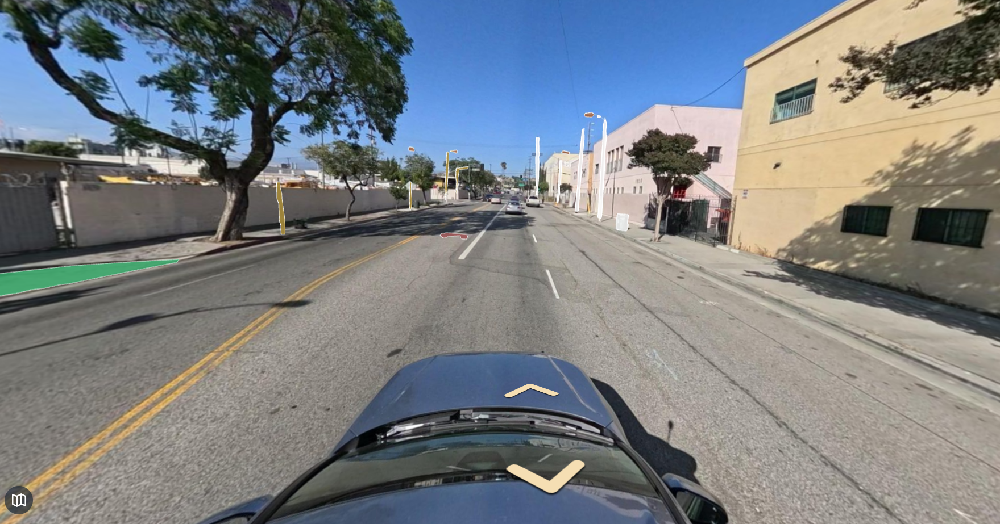

Loaded: {49F656A9-51D7-48E8-9A03-637BE33F64A1}.png
Image size: (1759, 923)
{
  "street": {
    "bicycle_facility_present": true,
    "permanent_dividing_median": null,
    "parking_separation": null,
    "permanent_civil_separation": null,
    "bus_boarding_island": null,
    "temporary_treatments": null,
    "striped_bike_lane": true,
    "physical_barrier_present": null,
    "flexible_posts_or_bollards": null
  },
  "lane_analysis": {
    "road_direction": "two-way",
    "same_direction_through_lanes": 1,
    "opposite_direction_through_lanes": 1,
    "total_through_lanes": 2,
    "turn_only_lanes": null,
    "parking_lanes": null,
    "centerline_type": "double yellow",
    "lane_markings": [
      "double yellow centerline",
      "white edge line on right",
      "yellow edge line on left"
    ],
    "lane_count_evidence": "Double yellow centerline separates two through lanes in each direction; camera is in the right through lane.",
    "uncertainty_reason": null
  },
  "intersect

### 4/17 — `{4C0615C4-C1A1-45CC-A0DF-62B714F7B47B}.png`

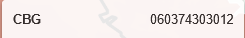

Loaded: {4C0615C4-C1A1-45CC-A0DF-62B714F7B47B}.png
Image size: (245, 38)
{
  "street": {
    "bicycle_facility_present": null,
    "permanent_dividing_median": null,
    "parking_separation": null,
    "permanent_civil_separation": null,
    "bus_boarding_island": null,
    "temporary_treatments": null,
    "striped_bike_lane": null,
    "physical_barrier_present": null,
    "flexible_posts_or_bollards": null
  },
  "lane_analysis": {
    "road_direction": "unknown",
    "same_direction_through_lanes": null,
    "opposite_direction_through_lanes": null,
    "total_through_lanes": null,
    "turn_only_lanes": null,
    "parking_lanes": null,
    "centerline_type": "unknown",
    "lane_markings": [],
    "lane_count_evidence": "",
    "uncertainty_reason": null
  },
  "intersection": {
    "intersection_visible": null,
    "controlled_intersection": null,
    "traffic_signal_present": null,
    "bike_box_present": null,
    "loop_detector_markings_visible": null,
    "rrfb_present": null

### 5/17 — `{4F395BE8-F9EE-429C-88A5-1CFC777BA3AD}.png`

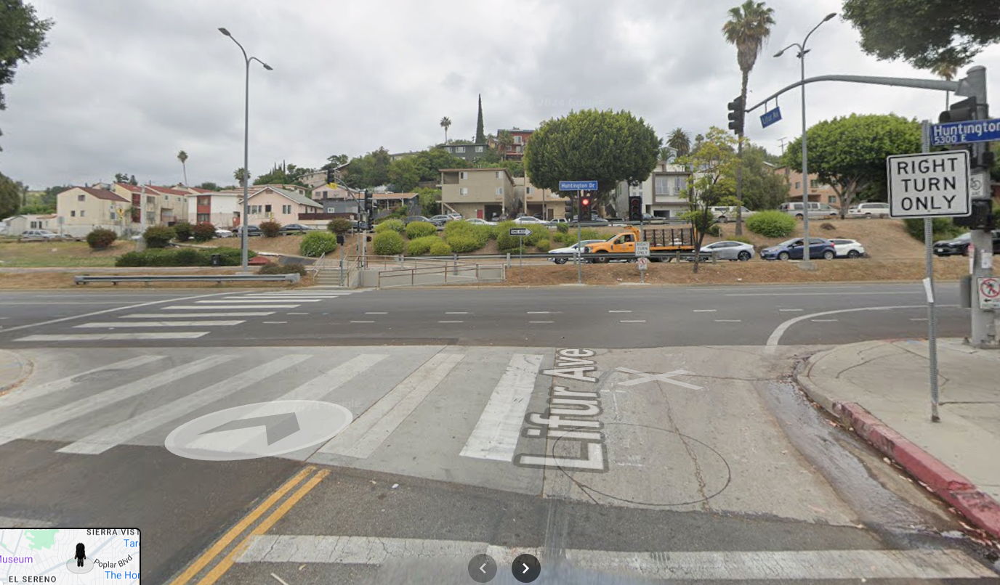

Loaded: {4F395BE8-F9EE-429C-88A5-1CFC777BA3AD}.png
Image size: (1376, 806)
{
  "street": {
    "bicycle_facility_present": null,
    "permanent_dividing_median": null,
    "parking_separation": null,
    "permanent_civil_separation": null,
    "bus_boarding_island": null,
    "temporary_treatments": null,
    "striped_bike_lane": null,
    "physical_barrier_present": null,
    "flexible_posts_or_bollards": null
  },
  "lane_analysis": {
    "road_direction": "unknown",
    "same_direction_through_lanes": 1,
    "opposite_direction_through_lanes": 2,
    "total_through_lanes": 3,
    "turn_only_lanes": 1,
    "parking_lanes": 0,
    "centerline_type": "double yellow",
    "lane_markings": [
      "double yellow centerline",
      "left turn arrow on crosswalk",
      "Littur Ave marking"
    ],
    "lane_count_evidence": "Double yellow centerline visible in foreground; same direction road has one through lane (left turn lane excluded); opposite direction has two through lanes (evidenced

### 6/17 — `{543907C2-AB9D-49CE-AD52-B88B8AE37081}.png`

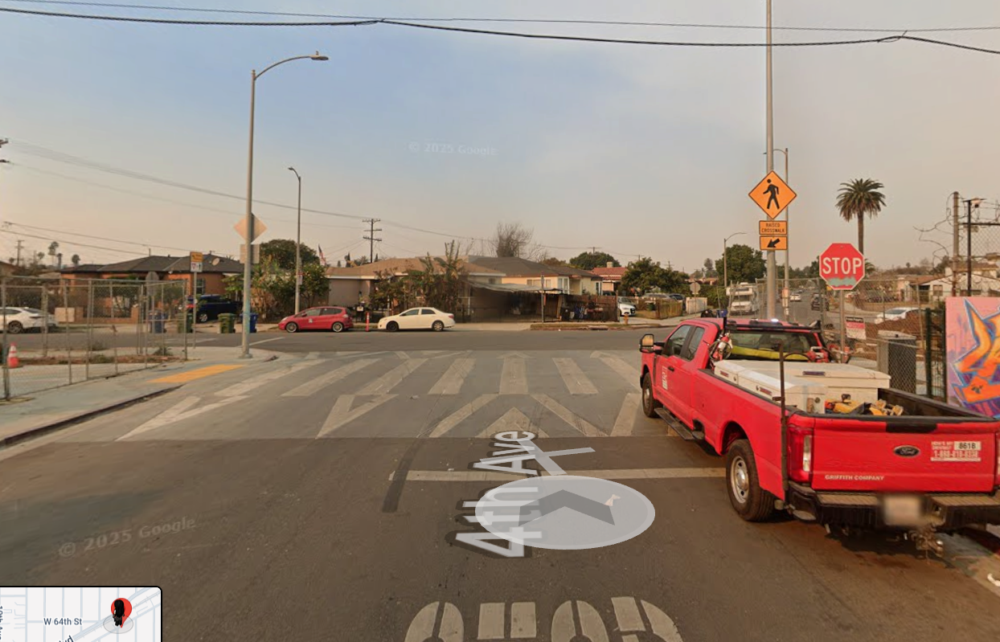

Loaded: {543907C2-AB9D-49CE-AD52-B88B8AE37081}.png
Image size: (1244, 799)
{
  "street": {
    "bicycle_facility_present": null,
    "permanent_dividing_median": null,
    "parking_separation": null,
    "permanent_civil_separation": null,
    "bus_boarding_island": null,
    "temporary_treatments": null,
    "striped_bike_lane": null,
    "physical_barrier_present": null,
    "flexible_posts_or_bollards": null
  },
  "lane_analysis": {
    "road_direction": "unknown",
    "same_direction_through_lanes": 2,
    "opposite_direction_through_lanes": 2,
    "total_through_lanes": 4,
    "turn_only_lanes": null,
    "parking_lanes": null,
    "centerline_type": "unknown",
    "lane_markings": [
      "crosswalk stripes",
      "road name marking (4th Ave)"
    ],
    "lane_count_evidence": "Crosswalk with multiple lanes and parked vehicles in the opposite direction indicating two through lanes per direction.",
    "uncertainty_reason": null
  },
  "intersection": {
    "intersection_visible

### 7/17 — `{5F88B8DD-27FE-494E-90C5-B0786E65131B}.png`

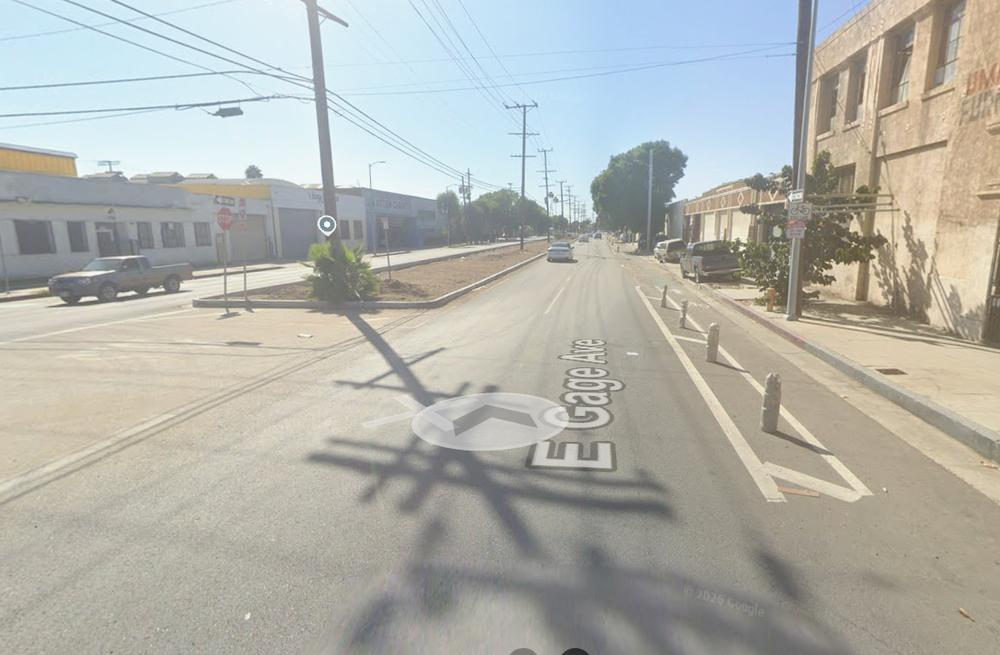

Loaded: {5F88B8DD-27FE-494E-90C5-B0786E65131B}.png
Image size: (1154, 756)


In [ ]:
from IPython.display import Markdown, display

image_paths = sorted(Path("data/streetview").glob("*.png"))

print(f"Found {len(image_paths)} image(s)")

for position, image_path in enumerate(image_paths, start=1):
    display(Markdown(f"### {position}/{len(image_paths)} — `{image_path.name}`"))

    with Image.open(image_path) as img:
        display(ImageOps.exif_transpose(img).convert("RGB"))

    raw = analyze_image(image_path)

    try:
        result = parse_result(raw)
    except ValueError as exc:
        print(f"Parse failed: {exc}\n\nRaw output:\n{raw}")
        continue

    print(json.dumps(result, indent=2))


In [15]:
import geopandas as gpd
from pathlib import Path

streets_df = gpd.read_file(Path("data/ladot_lts/LADOT_StressFreeStreets_091020.gdb"), layer='nen_streets_091020')
intersection_df = gpd.read_file(Path("data/ladot_lts/LADOT_StressFreeStreets_091020.gdb"), layer='nen_isec_091020')



In [10]:
streets_df.explore("LTS_ov")

In [14]:
intersection_df.explore("lts_isec")